# Section 5.1: Synthetic Gaussian Data-Generating Process

Reproduces **Fig. 1** of the paper (Sec. 5.1, App. D.1). We construct a fully controlled multivariate Gaussian DGP with $T = 4$ output components and $p = 4$ input features, where each feature plays a *known* role:

- $x_1$ drives the **mean** only, i.e., should be invisible to the uncertainty hierarchy at every level as it doesn't affect the predictive uncertainty.
- $x_2$ drives the **variance**, with an effect that grows with $t$.
- $x_3$ drives **variance and correlation** simultaneously.
- $x_4$ drives **correlation only**, leaving every marginal invariant and only affects the dependencies within the output components.

Because the entropy and conditional entropy of a multivariate Gaussian have closed forms (Sec. 4.2.1), we can compute every level analytically (up to Monte-Carlo noise) and verify that:

- **Proposition 1** (chain-rule linkage):
  $\phi^{\mathrm{joint}}(j, \mathbf{x}) = \sum_t \phi^{(t \mid <t)}(j, \mathbf{x})$.
- **Proposition 2** (cross-component decomposition):
  $\phi^{\mathrm{TC}}(j, \mathbf{x}) = \sum_t \phi^{(t)}(j, \mathbf{x}) - \phi^{\mathrm{joint}}(j, \mathbf{x})$.
- $x_4$ is the blind-spot example: it is invisible to Level 1 yet dominant at the cross-component term.

Fig. 1 is written to `plots/paper/synthetic_hierarchy.pdf`. Two extra figures, not in the paper, go to `plots/extra/`: the two instances with their predictive correlations (`predictive_distributions.pdf`) and the stability of the attributions over the number of backgrounds (`background_stability.pdf`). Intermediate results are written to `results/5_1/`. The notebook runs in a few minutes.

> **Note.** This notebook is intended to be executed top-to-bottom in a single run (e.g. *Run All*). The global NumPy RNG is seeded once at the top, so re-running individual cells out of order can change the background sample and shift Shapley values by Monte-Carlo noise.


In [1]:
import sys, os, time
sys.path.insert(0, os.path.join(os.path.abspath(""), ".."))
start_time = time.time()

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Polygon, Rectangle
from matplotlib import gridspec

# Import necessary classes of entropy_shapley
from entropy_shapley.game import HierarchyGame
from entropy_shapley.imputer import GaussianImputer
from entropy_shapley.sampler import MarginalTabularSampler

# Quick run: set QUICK_RUN=1 for a small background-stability run with separate output folders
QUICK_RUN = os.environ.get("QUICK_RUN") == "1"

# Output directories: figures of the paper and extra figures
plot_root = '../plots_quick' if QUICK_RUN else '../plots'
paper_dir, extra_dir = f'{plot_root}/paper', f'{plot_root}/extra'
res_dir = '../results_quick/5_1' if QUICK_RUN else '../results/5_1'
os.makedirs(paper_dir, exist_ok=True)
os.makedirs(extra_dir, exist_ok=True)
os.makedirs(res_dir, exist_ok=True)

# Reproducibility seed
seed = 123
np.random.seed(seed)


## 1) Data-Generating Process

| Feature | Symbol | Role |
|---------|--------|------|
| $x_1$ | `mean` | Drives **mean** $\mu_t(\mathbf{x}) = x_1 \sin(2\pi t / T)$ |
| $x_2$ | `var` | Drives **variance** (ascending effect over components)|
| $x_3$ | `var+corr` | Drives **variance** and **correlation** simultaneously (independent of $t$) |
| $x_4$ | `corr` | Drives **correlation** $\rho(\mathbf{x}) = \tanh(\delta_0 x_4 + \delta_1 x_3)$ (independent of $t$) |


In [2]:
# Global parameters
T = 4       # forecast components
p = 4       # features
N = 100    # samples for visualisation
N_BACKGROUND = 10_000  # background samples for Shapley value estimation

# Data generation parameters
beta  = 1.0             # effect of x1 on mean
gamma = [0.5, 0.8]      # effect of x2 and x3 on variance
delta = [-0.6, 1.25]    # effect of x3 and x4 on correlation

# Mu vector (only depends on x1)
def mu(x: np.ndarray) -> np.ndarray:
    t = np.arange(1, T + 1)
    return beta * x[..., 0:1] * np.sin(2 * np.pi * t / T)

# Sigma matrix (depends on x2, x3, x4)
def sigma(x: np.ndarray) -> np.ndarray:
    t        = np.arange(1, T + 1)

    # Variance depends on x2 and x3
    # D_tt = gamma[0] * x2 + gamma[1] * x3 * t
    s2       = np.exp(gamma[0] * x[..., 1:2] * t + gamma[1] * x[..., 2:3])
    D        = np.sqrt(s2)[..., None] * np.eye(T)

    # Correlation depends on x3 and x4
    # r = tanh(delta[0] * x3 + delta[1] * x4) to ensure |r| < 1
    # R_ij = sign(r) * |r|^(|i-j|^1.5) to ensure positive definiteness
    r        = np.tanh(delta[0] * x[..., 2:3] + delta[1] * x[..., 3:4])
    int_diff = np.abs(np.arange(T)[:, None] - np.arange(T)[None, :])
    R        = np.sign(r[..., None]) ** int_diff * np.abs(r[..., None]) ** (int_diff ** 1.5)
    
    return D @ R @ D

# Define DGP as the model
def GaussianModel(X):
    return sigma(X)   # (n, T, T)

## 2) Two Forecast Instances

We pick two instances with contrasting profiles:
- $\mathbf{x}_a = (1, 1, 1, 1.75)$: very high correlation ($\rho > 0$), moderate variance **(shown in the paper)**
- $\mathbf{x}_b = (-2, -1, 0.1, -0.2)$: negative mean, low correlation

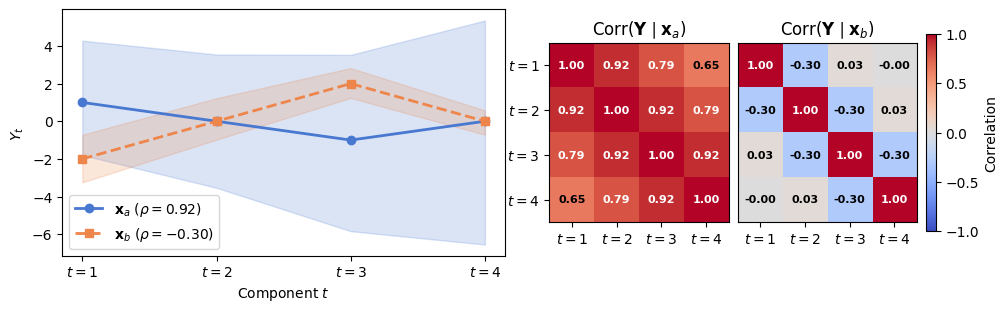

In [3]:
# Define two instances for visualisation
x_a = np.array([1, 1, 1, 1.75])
x_b = np.array([-2, -1, 0.1, -0.2])

# Compute Mu and Sigma for both instances
Mu_a, Mu_b = mu(x_a), mu(x_b)
Sigma_a, Sigma_b = sigma(x_a), sigma(x_b)

# Sample some trajectories for visualisation
Y_samp_a     = np.random.multivariate_normal(Mu_a, Sigma_a, N)
Y_samp_b     = np.random.multivariate_normal(Mu_b, Sigma_b, N)
q05_a, q95_a = np.quantile(Y_samp_a, [0.05, 0.95], axis=0)
q05_b, q95_b = np.quantile(Y_samp_b, [0.05, 0.95], axis=0)

# Compute correlation matrices and overall correlation strength for both instances
cov_to_corr = lambda S: S / np.sqrt(np.outer(np.diag(S), np.diag(S)))
R_a = cov_to_corr(Sigma_a)
R_b = cov_to_corr(Sigma_b)
rho_a = np.tanh(delta[0] * x_a[2] + delta[1] * x_a[3])
rho_b = np.tanh(delta[0] * x_b[2] + delta[1] * x_b[3])

# Define labels for plotting
t      = np.arange(1, T + 1)
labels = [f'$t={i}$' for i in t]

# Define colors for plotting
cols = sns.color_palette("muted", n_colors=2).as_hex()

# Create figure with nested grids
fig = plt.figure(figsize=(12, 3.2))
outer = gridspec.GridSpec(1, 2, width_ratios=[2, 2], wspace=0.1)
right = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer[1], wspace=0.05)

axes = [fig.add_subplot(outer[0]), fig.add_subplot(right[0]), fig.add_subplot(right[1])]
ax = axes[0]
ax.fill_between(t, q05_a, q95_a, alpha=0.2, color=cols[0])
ax.plot(t, Mu_a, 'o-', color=cols[0], linewidth=2,
        label=rf'$\mathbf{{x}}_a$ ($\rho={rho_a:.2f}$)')
ax.fill_between(t, q05_b, q95_b, alpha=0.2, color=cols[1])
ax.plot(t, Mu_b, 's--', color=cols[1], linewidth=2,
        label=rf'$\mathbf{{x}}_b$ ($\rho={rho_b:.2f}$)')
ax.set(xticks=t, xticklabels=labels, xlabel='Component $t$', ylabel='$Y_t$',
       title=None)
ax.legend()

def plot_corr(ax, R, title):
    im = ax.imshow(R, cmap='coolwarm', vmin=-1, vmax=1)
    ax.set(title=title, xticks=range(T), yticks=range(T),
           xticklabels=labels, yticklabels=labels)
    for i in range(T):
        for j in range(T):
            color = 'white' if abs(R[i, j]) > 0.7 else 'black'
            ax.text(j, i, f'{R[i,j]:.2f}', ha='center', va='center',
                    fontsize=8, color=color, fontweight='bold')
    return im

plot_corr(axes[1], R_a, r'$\mathrm{Corr}(\mathbf{Y} \mid \mathbf{x}_a)$')
im = plot_corr(axes[2], R_b, r'$\mathrm{Corr}(\mathbf{Y} \mid \mathbf{x}_b)$')
axes[2].set_yticks([])
fig.colorbar(im, ax=axes[1:], shrink=0.8, label='Correlation', pad=0.02)

# Save figure and show
fig.savefig(f'{extra_dir}/predictive_distributions.pdf', bbox_inches='tight')
plt.show()


## 3) Entropy-Shapley Hierarchy

We compute Shapley values for **three entropy levels** of the multivariate Gaussian:

| Level | Quantity | Intuition |
|-------|----------|-----------|
| **Level 1** | $H(Y_t \mid \mathbf{x})$ | Marginal forecast uncertainty at horizon $t$ |
| **Level 2** | $H(Y_t \mid Y_{<t}, \mathbf{x})$ | Conditional uncertainty given preceding timepoints $<t$ |
| **Level 3** | $H(\mathbf{Y} \mid \mathbf{x})$ | Joint uncertainty of the full trajectory |

The **cross-component attribution** $\phi^{\mathrm{TC}}(j, \mathbf{x}) = \sum_t \phi^{(t)}(j, \mathbf{x}) - \phi^{\text{joint}}(j, \mathbf{x})$ (Prop. 2)
captures how much feature $j$ changes the dependence between the output components.

We explain instance $\mathbf{x}_a$ using `GaussianImputer` with a marginal
background distribution ($K=10{,}000$ background samples).

In [4]:
x          = x_a
background = np.random.randn(N_BACKGROUND, p)

# Define imputer and game for Shapley value estimation
sampler = MarginalTabularSampler(background, sample_size=N_BACKGROUND)
imputer = GaussianImputer(GaussianModel, sampler, x, T)

# Run calculation using all subsets S
game    = HierarchyGame(imputer).precompute()

# Extract Shapley values
phi_L1      = np.stack([game.game_L1(t).exact_values('SII', order=1).values[1:] for t in range(T)])
phi_L2      = np.stack([game.game_L2(t).exact_values('SII', order=1).values[1:] for t in range(T)])
phi_L3      = game.game_L3().exact_values('SII', order=1).values[1:]
phi_cross_t = phi_L1 - phi_L2
phi_cross   = phi_L1.sum(axis=0) - phi_L3

# Store results in a dictionary
results = dict(phi_L1=phi_L1, phi_L2=phi_L2, phi_L3=phi_L3,
               phi_cross_t=phi_cross_t, phi_cross=phi_cross,
               x_a=x_a, x_b=x_b)

# Save results
np.savez(f'{res_dir}/shapley_values.npz', **results)

100%|██████████| 1/1 [00:00<00:00,  6.04it/s]


### Verification of Propositions 1 and 2

Sanity checks on the computed Shapley values:

- **Prop. 1 (chain rule):** $\phi^{\text{joint}}_j = \sum_t \phi^{(t|<t)}_j$.
- **Prop. 2 (TC game):** $\sum_j \phi^{\mathrm{TC}}_j = \mathrm{TC}(Y\mid x) - \mathrm{TC}(Y\mid X)$,
  where the right-hand side is computed analytically from the Gaussian covariance matrices over the background distribution.


In [5]:
# --- Prop. 1 (chain rule): phi_joint = sum_t phi_L2_t -----------------
prop1_residual = phi_L3 - phi_L2.sum(axis=0)
print(f"Prop. 1 (chain rule):  max |residual|     = {np.max(np.abs(prop1_residual)):.2e}")

# --- Prop. 2 (cross = TC game): sum_j phi_cross_j = TC(Y|x) - TC(Y|X) -
def total_corr_gauss(S):
    """Total correlation of multivariate Gaussian: 0.5 * (sum log diag - log det)."""
    diag_log  = np.log(np.diagonal(S, axis1=-2, axis2=-1)).sum(axis=-1)
    _, logdet = np.linalg.slogdet(S)
    return 0.5 * (diag_log - logdet)

TC_local  = total_corr_gauss(sigma(x))
TC_global = total_corr_gauss(sigma(background)).mean()
lhs, rhs  = phi_cross.sum(), TC_local - TC_global
print(f"Prop. 2 (cross = TC):  sum_j phi_cross_j   = {lhs: .6f}")
print(f"                       TC(Y|x) - TC(Y|X)   = {rhs: .6f}")
print(f"                       residual            = {lhs - rhs:.2e}")

# Hard assertions — these must hold for the paper claims to stand
assert np.max(np.abs(prop1_residual)) < 1e-8, "Prop. 1 (chain rule) violated"
assert abs(lhs - rhs) < 1e-3, "Prop. 2 (cross = TC) violated within MC tolerance"

# --- Qualitative DGP pattern: each feature carries only the role it was given ---
# x_1 enters only through the mean, so Sigma (and every entropy level) must ignore it.
# x_4 drives correlation only, so it is invisible at L1 but active at L2 / cross.
print(f"x_1 (mean only):       max |phi_L1[:,0]|   = {np.max(np.abs(phi_L1[:, 0])):.2e}")
print(f"                       max |phi_L2[:,0]|   = {np.max(np.abs(phi_L2[:, 0])):.2e}")
print(f"                       |phi_L3[0]|         = {abs(phi_L3[0]):.2e}")
print(f"x_4 (corr only):       max |phi_L1[:,3]|   = {np.max(np.abs(phi_L1[:, 3])):.2e}")
print(f"                       sum_t phi_L2[t,3]   = {phi_L2[:, 3].sum(): .6f}")
print(f"                       phi_cross[3]        = {phi_cross[3]: .6f}")

# Check 7: x_1 only drives the mean and gets zero attribution at every level.
from experiments.checks import check_null_players
check_null_players(results, [0], atol=1e-8)


Prop. 1 (chain rule):  max |residual|     = 2.79e-13
Prop. 2 (cross = TC):  sum_j phi_cross_j   =  1.020070
                       TC(Y|x) - TC(Y|X)   =  1.020070
                       residual            = -3.52e-13
x_1 (mean only):       max |phi_L1[:,0]|   = 1.11e-16
                       max |phi_L2[:,0]|   = 1.11e-16
                       |phi_L3[0]|         = 2.22e-16
x_4 (corr only):       max |phi_L1[:,3]|   = 1.11e-16
                       sum_t phi_L2[t,3]   = -1.885800
                       phi_cross[3]        =  1.885800


## 4) Create Visualization

The figure shows all three Shapley levels side by side.
Ribbons connect individual-horizon bars (Level 1/2) to their stacked aggregate,
making the decomposition $\sum_t \phi^{(t)}(j, \mathbf{x}) = \phi^{\text{joint}}(j, \mathbf{x}) + \phi^{\mathrm{TC}}(j, \mathbf{x})$ visual.

**Expected pattern** (by DGP design):
- $x_1$ (mean): not visible, since it only affects the mean and not the $\Sigma$
- $x_2$ (var): increasing mass at Level 1 (same as for Level 2).
- $x_3$ (var+corr): appears at both levels (but differently).
- $x_4$ (corr only): zero at Level 1, visible at Level 2.

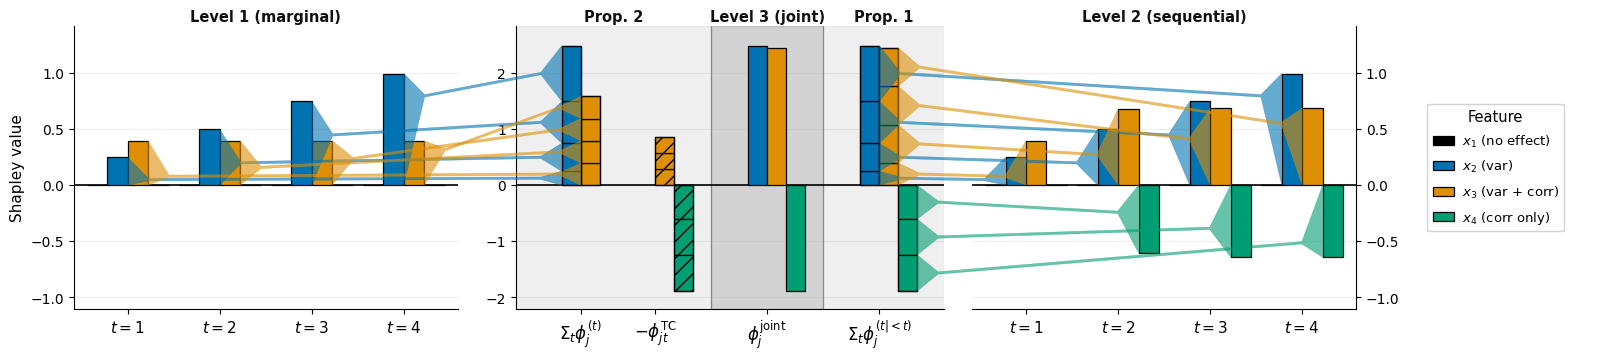

In [6]:
# Global setting --------------------------------------------------------------
FEATURE_ROLES = ['mean', 'var', 'var + corr', 'corr only']
FEAT_COLORS = ["#000000", *sns.color_palette("colorblind", n_colors=3).as_hex()]
FEAT_LABELS = [r'$x_1$ (no effect)', r'$x_2$ (var)', r'$x_3$ (var + corr)', r'$x_4$ (corr only)']
BW  = 0.16
TS  = 0.72
OFF = BW * np.array([-(p - 1) / 2 + j for j in range(p)])
t_local = np.arange(T, dtype=float) * TS
w_side = T * TS + 0.7

# Helper functions ------------------------------------------------------------
def draw_grouped(ax, vals, centers, labels=False):
    for j in range(p):
        kw = dict(color=FEAT_COLORS[j], zorder=3, edgecolor='black', lw=0.9)
        if labels: kw['label'] = FEAT_LABELS[j]
        ax.bar(centers + OFF[j], vals[:, j], BW, **kw)

def draw_stacked(ax, time_data, xc, hatch=None):
    for j in range(p):
        xp = xc + OFF[j];  bp, bn = 0.0, 0.0
        for t in range(T):
            v = float(time_data[t, j])
            if abs(v) < 1e-3: continue
            b = bp if v >= 0 else bn
            kw = dict(color=FEAT_COLORS[j], edgecolor='black', lw=0.9, zorder=3)
            if hatch: kw['hatch'] = hatch
            ax.bar(xp, v, BW, bottom=b, **kw)
            if v >= 0: bp += v
            else:      bn += v
        tot = float(time_data[:, j].sum())
        if abs(tot) > 1e-3:
            ax.add_patch(Rectangle((xp - BW/2, min(0., tot)), BW, abs(tot),
                fill=False, edgecolor='black', lw=0.9, zorder=4))

def draw_vec(ax, vec, xc, hatch=None):
    for j in range(p):
        v = float(vec[j])
        if abs(v) < 1e-3: continue
        kw = dict(color=FEAT_COLORS[j], edgecolor='black', lw=0.9, zorder=3)
        if hatch: kw['hatch'] = hatch
        ax.bar(xc + OFF[j], v, BW, **kw)

def stk_bounds(phi):
    segs = {}
    for j in range(p):
        pos, neg = 0.0, 0.0
        for t in range(T):
            v = float(phi[t, j])
            if v >= 0: segs[(j, t)] = (pos, pos + v); pos += v
            else:      segs[(j, t)] = (neg + v, neg);  neg += v
    return segs

def ribbon(ax_s, xs, ys_b, ys_t, ax_t, xt, yt_b, yt_t,
           color, t_idx, val, pin_src=True, pin_tgt=False,
           narrow=0.013, thin=0.007, alpha=0.6):
    def tf(ax, x, y):
        return (ax.transData + fig.transFigure.inverted()).transform((x, y))
    sx,  sy_t = tf(ax_s, xs, ys_t)
    _,   sy_b = tf(ax_s, xs, ys_b)
    tx,  ty_t = tf(ax_t, xt, yt_t)
    _,   ty_b = tf(ax_t, xt, yt_b)
    base_frac = (t_idx + 1) / (T + 1)
    frac      = base_frac if val >= 0 else 1 - base_frac
    sy_pin    = sy_b + frac * (sy_t - sy_b) if pin_src else (sy_t + sy_b) / 2
    ty_pin    = ty_b + frac * (ty_t - ty_b) if pin_tgt else (ty_t + ty_b) / 2
    pts = np.array([
        [sx,           sy_t           ],
        [sx + narrow,  sy_pin + thin/2],
        [tx - narrow,  ty_pin + thin/2],
        [tx,           ty_t           ],
        [tx,           ty_b           ],
        [tx - narrow,  ty_pin - thin/2],
        [sx + narrow,  sy_pin - thin/2],
        [sx,           sy_b           ],
    ])
    fig.add_artist(Polygon(pts, closed=True, facecolor=color,
        alpha=alpha, edgecolor=color, lw=0.3,
        transform=fig.transFigure, clip_on=False))

def fmt_ax(ax, xlim, sections, ylabel=None, hide_left=False, hide_right=False):
    ax.set_xlim(*xlim)
    ax.axhline(0, color='black', lw=1.2, zorder=2)
    ax.grid(axis='y', lw=0.4, alpha=0.4, zorder=1)
    ax.spines['top'].set_visible(False)
    if hide_left:
        ax.spines['left'].set_visible(False)
        ax.tick_params(left=False, labelleft=False)
    if hide_right:
        ax.spines['right'].set_visible(False)
    if ylabel: ax.set_ylabel(ylabel, fontsize=11)
    tr = ax.get_xaxis_transform()
    for i, (x1, x2, color, label) in enumerate(sections):
        ax.axvspan(x1, x2, color=color, alpha=0.35, zorder=0)
        if i > 0: ax.axvline(x1, color='#888', lw=0.8, zorder=1)
        ax.text((x1+x2)/2, 1.005, label, ha='center', va='bottom',
                fontsize=10.5, color='#111', transform=tr,
                fontweight='bold')


# Create plot -----------------------------------------------------------------
fig = plt.figure(figsize=(16, 3.5), layout='constrained')
gs   = fig.add_gridspec(1, 4, width_ratios=[w_side, 4.0, w_side, 1.55], wspace=0.07)
ax_l   = fig.add_subplot(gs[0])
ax_m   = fig.add_subplot(gs[1])
ax_r   = fig.add_subplot(gs[2])
ax_leg = fig.add_subplot(gs[3]); ax_leg.axis('off')

sl1 = 0.55;  crx = sl1 + 0.63;  jx = crx + 0.95;  sl2 = jx + 0.95
x_lo_m, x_hi_m = 0.0, sl2 + 0.55
sep_B_m = (crx + jx) / 2;  sep_C_m = (jx + sl2) / 2

draw_grouped(ax_l, phi_L1, t_local, labels=True)
draw_stacked(ax_m, phi_L1, sl1)
draw_stacked(ax_m, -phi_cross_t, crx, hatch='//')
draw_vec(ax_m, phi_L3, jx)
draw_stacked(ax_m, phi_L2, sl2)
draw_grouped(ax_r, phi_L2, t_local)

x_lo_l, x_hi_l = t_local[0] - 0.42, t_local[-1] + 0.42
fmt_ax(ax_l, (x_lo_l, x_hi_l), [(x_lo_l, x_hi_l, 'white', 'Level 1 (marginal)')],
       ylabel='Shapley value', hide_right=True)
fmt_ax(ax_m, (x_lo_m, x_hi_m),
       [(x_lo_m,  sep_B_m, 'lightgray', 'Prop. 2'),
        (sep_B_m, sep_C_m, 'gray',      'Level 3 (joint)'),
        (sep_C_m, x_hi_m,  'lightgray', 'Prop. 1')],
       hide_right=True)
fmt_ax(ax_r, (x_lo_l, x_hi_l), [(x_lo_l, x_hi_l, 'white', 'Level 2 (sequential)')],
       hide_left=True)
ax_r.spines['right'].set_visible(True)
ax_r.tick_params(right=True, labelright=True)

t_labs = [f'$t={i+1}$' for i in range(T)]
ax_l.set_xticks(t_local); ax_l.set_xticklabels(t_labs, fontsize=11)
ax_m.set_xticks([sl1, crx, jx, sl2])
ax_m.set_xticklabels([
    r'$\Sigma_t\phi^{(t)}_j$', r'$-\phi^{\rm TC}_{jt}$',
    r'$\phi^{\rm joint}_j$',   r'$\Sigma_t\phi^{(t|{<}t)}_j$',
], fontsize=12)
ax_r.set_xticks(t_local); ax_r.set_xticklabels(t_labs, fontsize=11)
for ax in (ax_l, ax_m, ax_r):
    ax.tick_params(axis='y', labelsize=10)

handles, labels_leg = ax_l.get_legend_handles_labels()
ax_leg.legend(handles, labels_leg, fontsize=9.5, ncols=1, title='Feature',
              title_fontsize=10.5, framealpha=0.9,
              loc='center left', bbox_to_anchor=(-0.05, 0.5),
              borderaxespad=0., handlelength=1.6, handletextpad=0.6,
              labelspacing=0.7)

fig.canvas.draw()
y_max = max(v for ax in [ax_l, ax_m, ax_r] for v in ax.get_ylim()) * 1.05
y_min = min(v for ax in [ax_l, ax_m, ax_r] for v in ax.get_ylim()) * 1.05
ax_m.set_ylim(y_min, y_max)
ax_l.set_ylim(y_min / 2, y_max / 2)
ax_r.set_ylim(y_min / 2, y_max / 2)
fig.canvas.draw()  # re-run constrained layout with final ylims before computing ribbon coords


segs1 = stk_bounds(phi_L1)
segs2 = stk_bounds(phi_L2)
for j in range(p):
    for t in range(T):
        v1 = float(phi_L1[t, j])
        if abs(v1) > 1e-2:
            yb, yt_ = segs1[(j, t)]
            ribbon(ax_l, t_local[t] + OFF[j] + BW/2, min(0., v1), max(0., v1),
                   ax_m, sl1        + OFF[j] - BW/2, yb, yt_,
                   FEAT_COLORS[j], t_idx=t, val=v1, pin_src=True, pin_tgt=False)
        v2 = float(phi_L2[t, j])
        if abs(v2) > 1e-2:
            yb, yt_ = segs2[(j, t)]
            ribbon(ax_m, sl2        + OFF[j] + BW/2, yb, yt_,
                   ax_r, t_local[t] + OFF[j] - BW/2, min(0., v2), max(0., v2),
                   FEAT_COLORS[j], t_idx=t, val=v2, pin_src=False, pin_tgt=True)


# Save figure
fig.savefig(f'{paper_dir}/synthetic_hierarchy.pdf', bbox_inches='tight')
fig.savefig(f'{paper_dir}/synthetic_hierarchy.png', bbox_inches='tight', dpi=200)
plt.show()


In [7]:
print("Done with the hierarchy of the Gaussian DGP")
print(f"Total runtime: {(time.time() - start_time):.2f} seconds")

Done with the hierarchy of the Gaussian DGP
Total runtime: 2.99 seconds


## 5) Background stability

The attributions are Monte Carlo averages over the $K$ background samples (Sec. 4.2), so they vary with the background draw. Without any output sampling, we draw 200 independent backgrounds and compute all levels exactly for several $K$ (smaller $K$ use the first rows of the same draw).

The figure shows the attributions of the Fig. 1 instance $\mathbf{x}_a$ over $K$: for each feature the mean over the draws (line) and their 5–95 % quantiles (band). Vertical lines mark $K = 25$ (semi-synthetic benchmark) and $K = 100$ (model comparison, Fig. 3b); Fig. 1 uses $K = 10\,000$. The table gives the relative spread of the attributions (standard deviation over the draws divided by the norm of their mean), as the median over 50 random instances.

In [8]:
import contextlib, io
import pandas as pd
from joblib import Parallel, delayed
from entropy_shapley.game import hierarchy_attributions
from experiments.checks import check_hierarchy

A_INSTANCES = 5 if QUICK_RUN else 50
A_REPEATS   = 10 if QUICK_RUN else 200
A_K_GRID    = (16, 25, 32, 100, 128, 512, 2048, 10_000)
COALITIONS  = ((np.arange(2 ** p)[:, None] >> np.arange(p)) & 1).astype(bool)
LEVELS      = {'L1': 'phi_L1', 'L2': 'phi_L2', 'Joint': 'phi_L3', 'TC': 'phi_cross'}
# Random instances for the table; the last row is the Fig. 1 instance for the figure.
x_inputs    = np.vstack([np.random.default_rng(41001).normal(size=(A_INSTANCES, p)), x_a])

def attributions_over_K(b):
    """Exact attributions of all instances for every K, with background draw b."""
    background = np.random.default_rng([42001, b]).normal(size=(max(A_K_GRID), p))
    phis = {level: [] for level in LEVELS}
    for K in A_K_GRID:
        imputer = GaussianImputer(GaussianModel, MarginalTabularSampler(background[:K]), x_inputs, T, chunk_size=1000)
        with contextlib.redirect_stderr(io.StringIO()):   # no progress bar per imputer call
            L1, L2, L3 = imputer(COALITIONS)
        hierarchy = dict(L1=L1, L2=L2, L3=L3)
        phi = hierarchy_attributions(hierarchy, p)
        check_hierarchy(hierarchy, phi)
        for level, key in LEVELS.items():
            phis[level].append(phi[key].reshape(len(x_inputs), -1))
    return {level: np.stack(values) for level, values in phis.items()}   # (K, instance, values)

runs  = Parallel(n_jobs=min(24, os.cpu_count()))(delayed(attributions_over_K)(b) for b in range(A_REPEATS))
draws = {level: np.stack([run[level] for run in runs]) for level in LEVELS}   # (draw, K, instance, values)

# Relative spread per random instance and K, then the median over the instances.
spread = {}
for level, d in draws.items():
    d = d[:, :, :-1]
    sd = np.sqrt(((d - d.mean(axis=0)) ** 2).sum(axis=(0, 3)) / (A_REPEATS - 1))   # (K, instance)
    spread[level] = np.median(sd / np.linalg.norm(d.mean(axis=0), axis=-1), axis=1)
stability = pd.DataFrame(spread, index=pd.Index(A_K_GRID, name='K'))
stability.to_csv(f'{res_dir}/background_stability.csv')
print('Relative spread of the attributions (median over the instances):')
print(stability.round(3).to_string())

Relative spread of the attributions (median over the instances):
          L1     L2  Joint     TC
K                                
16     0.298  0.331  0.318  0.423
25     0.234  0.260  0.250  0.337
32     0.214  0.238  0.229  0.307
100    0.121  0.134  0.131  0.165
128    0.109  0.122  0.118  0.152
512    0.055  0.060  0.058  0.076
2048   0.025  0.028  0.027  0.038
10000  0.012  0.014  0.013  0.018


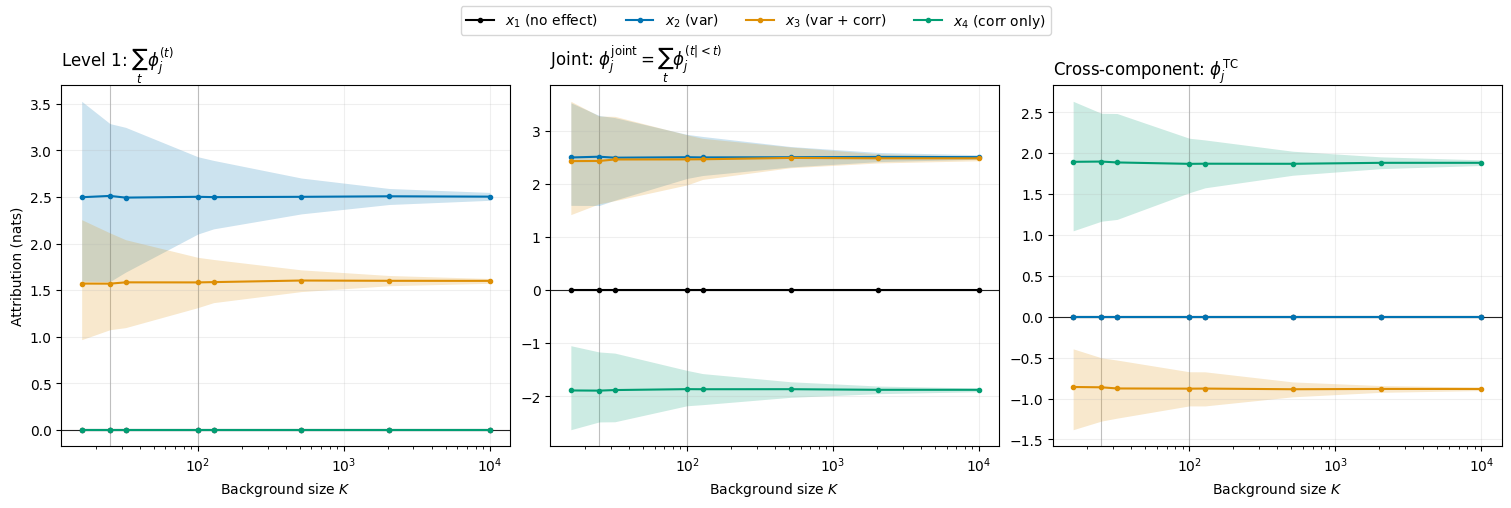

In [9]:
# Attributions of the Fig. 1 instance over K (mean and 5-95 % quantiles over the
# background draws), in the feature colors of Fig. 1.
PANELS = {'L1': r'Level 1: $\sum_t \phi_j^{(t)}$',
          'Joint': r'Joint: $\phi_j^{\mathrm{joint}} = \sum_t \phi_j^{(t|<t)}$',
          'TC': r'Cross-component: $\phi_j^{\mathrm{TC}}$'}
K_grid = np.array(A_K_GRID)
fig, axes = plt.subplots(1, 3, figsize=(15, 5), layout='constrained')
for ax, (level, title) in zip(axes, PANELS.items()):
    d = draws[level][:, :, -1]                                # (draw, K, values) of the Fig. 1 instance
    if level == 'L1':                                         # sum over the components t
        d = d.reshape(*d.shape[:2], T, p).sum(axis=2)
    low, high = np.quantile(d, [.05, .95], axis=0)
    for j in range(p):
        ax.fill_between(K_grid, low[:, j], high[:, j], color=FEAT_COLORS[j], alpha=.2, lw=0)
        ax.plot(K_grid, d.mean(axis=0)[:, j], color=FEAT_COLORS[j], marker='o', markersize=3, label=FEAT_LABELS[j])
    for K in (25, 100):
        ax.axvline(K, color='0.75', lw=.8, zorder=0)
    ax.axhline(0, color='black', lw=.8, zorder=0)
    ax.set(xscale='log', xlabel='Background size $K$')
    ax.set_title(title, loc='left')
    ax.grid(alpha=.2)
axes[0].set_ylabel('Attribution (nats)')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside upper center', ncol=p)
fig.savefig(f'{extra_dir}/background_stability.pdf')
plt.show()

In [10]:
print("Done with the entire script, including the background-stability experiment")
print(f"Total runtime: {(time.time() - start_time):.2f} seconds")

Done with the entire script, including the background-stability experiment
Total runtime: 138.51 seconds
